# 수치방법과 실험 설정 · Generalized Black–Scholes equation

논문 §5의 두 수치실험에서 사용하는 모델, 격자, 차분식과 오차 정의를 설명한다. §2의 payoff smoothing, §3의 공간·시간 이산화, §4에서 실험에 사용할 결과를 필요한 만큼 정리한다. 계산 셀은 **xeus-cpp의 C++17**로 실행한다.

이 노트북에서 공통 수치방법과 실험 설정을 먼저 확인한 뒤, 다음 두 노트북을 Test 1, Test 2 순서로 읽는다.

| 실험 | 재현 대상 |
|---|---|
| [Test 1](5_1_Test_1_Figure_1_Table_1.ipynb) | 시공간 의존 변동성, Figure 1 및 Table 1 |
| [Test 2](5_2_Test_2_Figure_2_Table_2.ipynb) | 공간 의존 변동성, Figure 2 및 Table 2 |

각 실험 노트북은 독립적으로 실행할 수 있다. `C++17 (Black–Scholes, xeus-cpp)` 커널을 선택하고 작업 디렉터리를 `ipynb/`로 둔다.

## 바로 사용하는 모델과 결과

$$Lu=-u_t-\tfrac12\sigma^2(x,t)x^2u_{xx}-r(t)xu_x+r(t)u=0.$$

$$u(x,T)=\pi_\varepsilon(x-K),\qquad u(0,t)=0,\qquad
u(S_{\max},t)=S_{\max}-K\exp\left(-\int_t^T r(s)\,ds\right).$$

이번 두 실험은 $r=0.06$이므로 오른쪽 경계는 $S_{\max}-Ke^{-r(T-t)}$이다.

| 결과 | 실험에서 사용하는 내용 |
|---|---|
| Lemma 1 | 내부 행렬의 M-matrix 조건을 확인하여 단조성과 안정성을 점검한다. |
| Theorem 1 | 공간 2차·시간 1차 수렴률 $O(h^2+\tau)$. |
| 식 (2.13) | payoff smoothing 오차와 이산화 오차를 구별한다. |

In [1]:
#include <cstdio>
#include <cmath>
#include <chrono>
#include "../include/BlackScholesSolver.h"
#include "../include/ErrorAnalysis.h"
#include "../include/ExperimentOutput.h"
#include "../include/NotebookDisplay.h"

prepareOutput();
printf("C++17 | xeus-cpp | central difference + implicit Euler + Thomas\n");

C++17 | xeus-cpp | central difference + implicit Euler + Thomas


## 수식과 코드의 표기 대응

| 수식 표기 | C++ | 의미 |
|---|---|---|
| $N,M$ | `N`, `M` | 공간·시간 구간 수; 점은 각각 $N+1,M+1$개 |
| $x_i,t_j$ | `x[i]`, `j*tau` | 원래 자산가격·시간 좌표 |
| $h_i=x_i-x_{i-1}$ | `h[i]` | 실제 공간 간격 ($i=1,\ldots,N$) |
| $\tau=T/M$ | `tau` | 시간 간격, 잔존만기와 구별 |
| $U_i^j$ | `value(i,j)` | 내부 저장은 `U[j*(N+1)+i]` |
| $A_i^j,B_i^j,C_i^j$ | `A[i]`, `B[i]`, `C[i]` | 현재 시간층의 삼중대각 계수 |
| $\alpha,\beta^*$ | `alpha`, `betaStar` | $\sigma^2\ge\alpha$, $r\le\beta^*$ |
| §3의 $h$ | `baseH` | $x_1$을 정하는 기준 간격 |

$U_i^M$을 먼저 놓고 $j=M-1,\ldots,0$ 순으로 푼다. `double*`, `new[]/delete[]`, 명시적인 반복문, `printf`, 이름 있는 풀이 메서드는 기존 `thomas_class` 스타일을 따른다.

## Payoff smoothing · 식 (2.10)

$y=x-K$, $z=y/\varepsilon$라 두면

$$\pi_\varepsilon(y)=\begin{cases}
0,&y\le-\varepsilon,\\
\varepsilon\left(\frac{35}{256}+\frac z2+\frac{35z^2}{64}-\frac{35z^4}{128}+\frac{7z^6}{64}-\frac{5z^8}{256}\right),&|y|<\varepsilon,\\
y,&y\ge\varepsilon.
\end{cases}$$

$z$를 사용하여 smoothing 다항식을 계산한다. 아래 그림은 좁은 smoothing 구간을 볼 수 있도록 가로축을 $(x-K)/\varepsilon$로 표시한다.

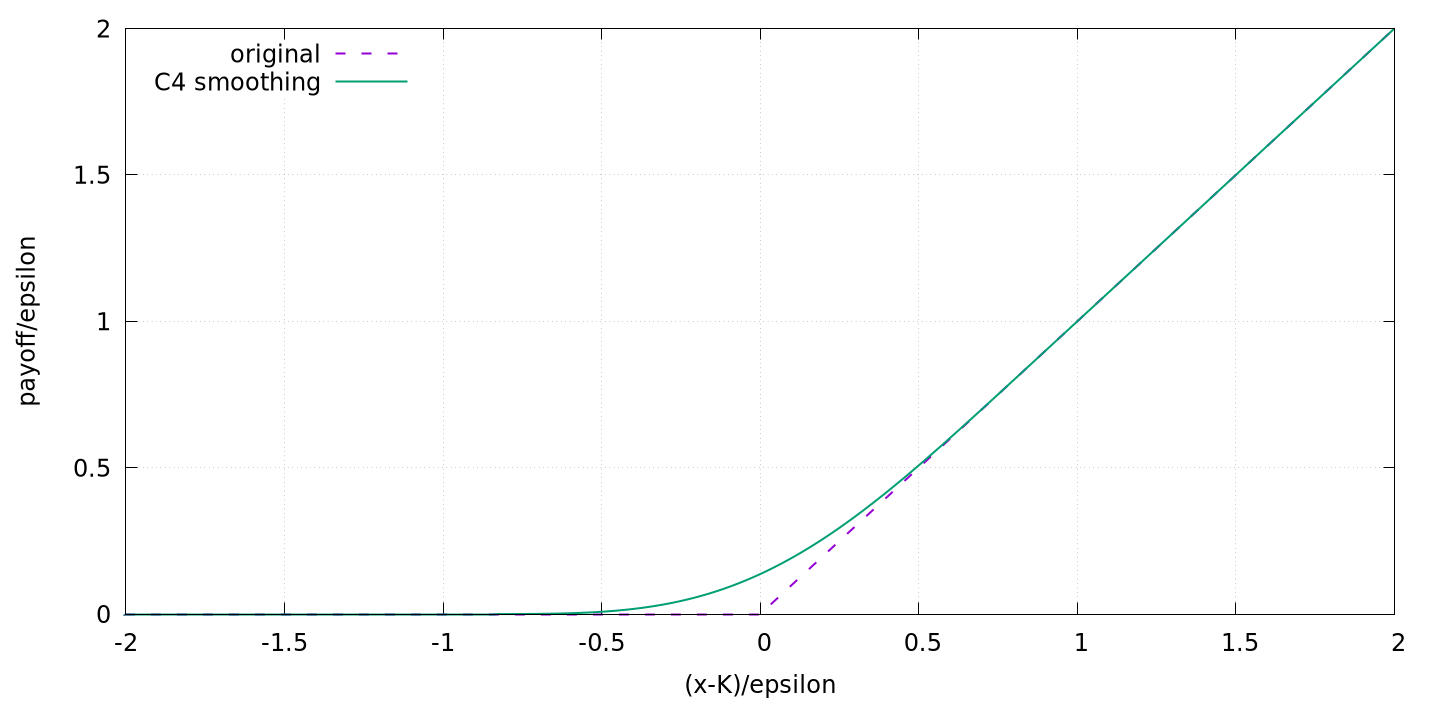

epsilon = 1.0e-04, pi_epsilon(0) = 1.3671875000e-05
max payoff perturbation = 35*epsilon/256 = 1.3671875000e-05


In [2]:
BlackScholesSolver common(64, 64, 0.04, 0.06);
printf("epsilon = %.1e, pi_epsilon(0) = %.10e\n", common.epsilon, common.payoff(0.0));
printf("max payoff perturbation = 35*epsilon/256 = %.10e\n", 35.0*common.epsilon/256.0);
FILE* payoffData = openOutput("../results/common_payoff.csv");
fprintf(payoffData, "z,original_over_epsilon,smoothed_over_epsilon\n");
for(int k=0; k<=400; k++)
{
    double z = -2.0 + 4.0*k/400;
    double original = z > 0.0 ? z : 0.0;
    fprintf(payoffData, "%.17g,%.17g,%.17g\n", z, original, common.payoff(z*common.epsilon)/common.epsilon);
}
fclose(payoffData);
FILE* payoffPlot = openOutput("../results/common_payoff.gp");
fprintf(payoffPlot, "set terminal svg size 900,440 font 'sans,13'\nset output '../results/common_payoff.svg'\n");
fprintf(payoffPlot, "set datafile separator ','; set grid; set key top left\nset xlabel '(x-K)/epsilon'; set ylabel 'payoff/epsilon'\n");
fprintf(payoffPlot, "plot '../results/common_payoff.csv' using 1:2 with lines dt 2 lw 2 title 'original', '' using 1:3 with lines lw 2 title 'C4 smoothing'\n");
fprintf(payoffPlot, "set terminal pngcairo size 1440,704 font 'sans,18'\nset output '../results/common_payoff.png'; replot\n");
fclose(payoffPlot);
runGnuplot("../results/common_payoff.gp");
displayPNG("../results/common_payoff.png");

## Piecewise uniform mesh · §3

$q=N/4$이고 $N$은 4의 배수이다. 논문의 격자는

$$h=\frac{K-\varepsilon}{1+(\alpha/\beta^*)(q-2)},\qquad x_0=0,$$
$$x_i=\begin{cases}
h[1+(\alpha/\beta^*)(i-1)],&1\le i<q,\\
K,&i=q,\\
K+\varepsilon,&i=q+1,\\
K+\varepsilon+\dfrac{S_{\max}-K-\varepsilon}{3N/4-1}(i-q-1),&q+2\le i\le N.
\end{cases}$$

따라서 $x_{q-1}=K-\varepsilon$, $x_q=K$, $x_{q+1}=K+\varepsilon$이다. Test 1에서는 $\alpha=0.2^2=0.04$, Test 2에서는 $\alpha=0.4^2=0.16$을 사용한다. 두 경우 모두 $\beta^*=0.06$. 이 값들은 주어진 계수의 최선의 하한·상한이다.

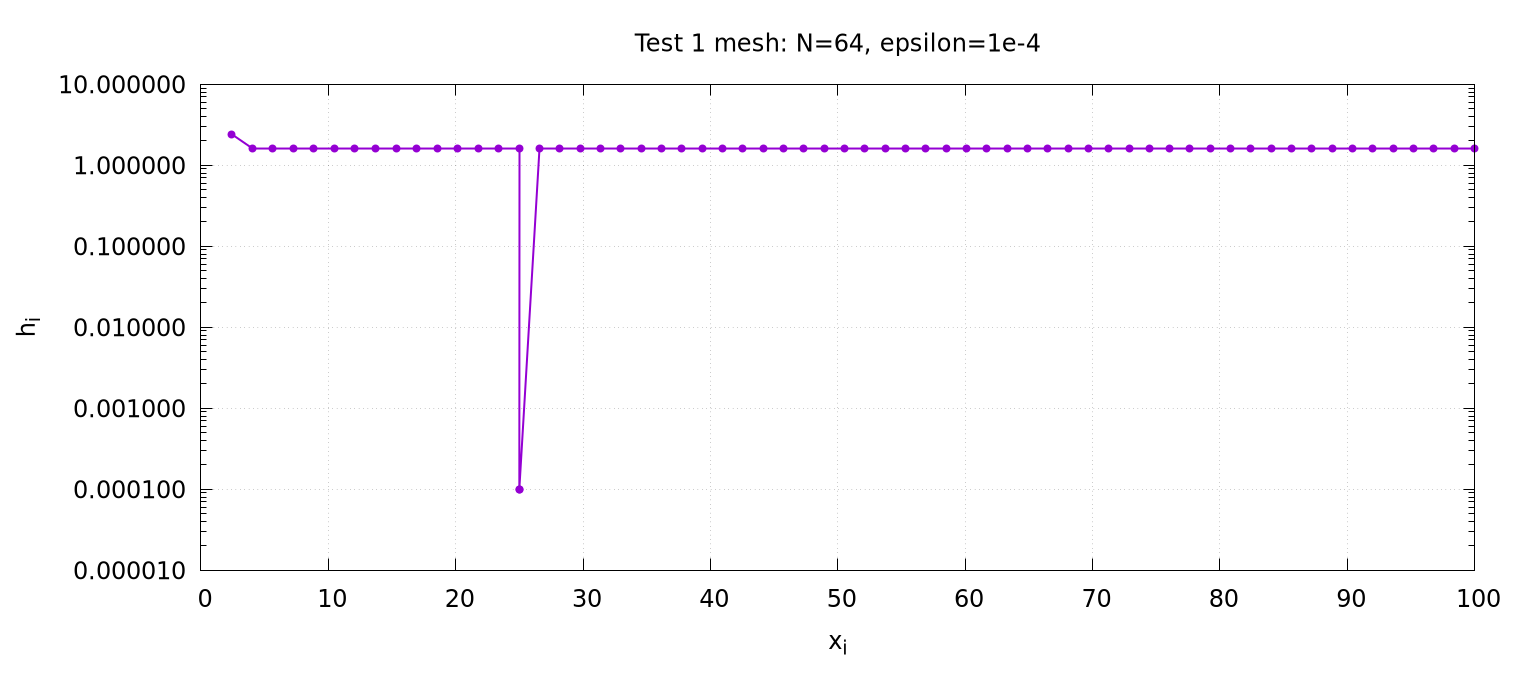

N=64, M=64, base h=2.419345161, tau=0.015625
    i             x_i             h_i
    1      2.41934516  2.41934516e+00
    2      4.03224194  1.61289677e+00
   15     24.99990000  1.61289677e+00
   16     25.00000000  1.00000000e-04
   17     25.00010000  1.00000000e-04
   18     26.59584255  1.59574255e+00
   64    100.00000000  1.59574255e+00


In [3]:
printf("N=%d, M=%d, base h=%.10g, tau=%.10g\n", common.N, common.M, common.baseH, common.tau);
printf("    i             x_i             h_i\n");
int meshIndices[] = {1, 2, 15, 16, 17, 18, 64};
for(int k=0; k<7; k++)
{
    int i = meshIndices[k];
    printf("%5d %15.8f %15.8e\n", i, common.x[i], common.h[i]);
}
FILE* meshData = openOutput("../results/common_mesh.csv");
fprintf(meshData, "i,x_i,h_i\n");
for(int i=1; i<=common.N; i++)
    fprintf(meshData, "%d,%.17g,%.17g\n", i, common.x[i], common.h[i]);
fclose(meshData);
FILE* meshPlot = openOutput("../results/common_mesh.gp");
fprintf(meshPlot, "set terminal svg size 950,430 font 'sans,13'\nset output '../results/common_mesh.svg'\n");
fprintf(meshPlot, "set datafile separator ','; set grid; set logscale y; set xlabel 'x_i'; set ylabel 'h_i'; set key off\n");
fprintf(meshPlot, "set title 'Test 1 mesh: N=64, epsilon=1e-4'\nplot '../results/common_mesh.csv' using 2:3 with linespoints pt 7 lw 2\n");
fprintf(meshPlot, "set terminal pngcairo size 1520,688 font 'sans,18'\nset output '../results/common_mesh.png'; replot\n");
fclose(meshPlot);
runGnuplot("../results/common_mesh.gp");
displayPNG("../results/common_mesh.png");

## Central difference + implicit Euler + Thomas

논문 식 (3.1)을 삼중대각 계수로 쓰면

$$L^{N,M}U_i^j=A_i^jU_{i-1}^j+B_i^jU_i^j+C_i^jU_{i+1}^j-\frac{U_i^{j+1}}{\tau}=0,$$

$$A_i^j=-\frac{x_i}{h_i+h_{i+1}}\left[\frac{(\sigma_i^j)^2x_i}{h_i}-r^j\right],$$
$$B_i^j=\frac1\tau+\frac{(\sigma_i^j)^2x_i^2}{h_ih_{i+1}}+r^j,\qquad
C_i^j=-\frac{x_i}{h_i+h_{i+1}}\left[\frac{(\sigma_i^j)^2x_i}{h_{i+1}}+r^j\right].$$

각 시간층에서는 $N-1$개의 내부 미지수만 Thomas algorithm으로 푼다. 우변은 $U_i^{j+1}/\tau$이고, 첫·마지막 행에서 각각 $A_1^jU_0^j$, $C_{N-1}^jU_N^j$를 뺀다.

구현: `BlackScholesSolver.h`의 `assembleCoefficients`, `step`, `solveTest1`과 `TridiagonalSolver.h`의 `solve`. 내부 행렬의 비대각 부호를 검사할 때 **$A_1^j$와 $C_{N-1}^j$는 경계 계수**이므로 제외한다. 아래 출력은 계산이 끝난 $j=0$ 시간층의 진단이다.

In [4]:
common.solveTest1();
printf("j=0: max interior off-diagonal = %.8e\n", common.largestInteriorOffDiagonal());
printf("j=0: min diagonal dominance margin = %.8e\n", common.minimumDiagonalMargin());
printf("A_1^0 (boundary coefficient, excluded above) = %.8e\n", common.A[1]);
printf("minimum U over all i,j = %.8e\n", ErrorAnalysis::minimumValue(common));
printf("U(K,0) = %.10f, U(K,T) = %.10e\n", common.value(common.N/4,0), common.value(common.N/4,common.M));

j=0: max interior off-diagonal = -5.00000000e-02
j=0: min diagonal dominance margin = 6.40480000e+01
A_1^0 (boundary coefficient, excluded above) = 1.20000000e-02
minimum U over all i,j = 0.00000000e+00
U(K,0) = 2.7168318788, U(K,T) = 1.3671875000e-05


경계 계수 $A_1^0$는 알려진 $U_0^0=0$에 곱해진다. 내부 행렬의 비대각 계수와 대각우세 여유를 함께 출력한다.

## 오차와 관측 수렴률 · §5

Figure 1·2에는 $N=M=64$를 사용한다. Table 1·2에는 $M=1024$를 고정하고 $N=128,256,512,1024$를 사용한다. 참조해는 $U^{2048,1024}$이며, 같은 $t_j$에서 공간 선형 보간한 값을 $\bar U(x_i,t_j)$라 쓴다.

$$e^{N,M}=\max_{0\le i\le N,\,0\le j\le M}|U_i^j-\bar U(x_i,t_j)|,\qquad
\bar r^{N,M}=\log_2\frac{e^{N,M}}{e^{2N,M}}.$$

- 오차의 최댓값은 모든 공간 노드와 시간층에서 구한다.
- 각 $N$에 대해 공간 격자를 생성하고, 참조해를 $x_i$ 좌표에서 선형 보간한다.
- 표의 수렴률은 현재 행 $N$과 다음 행 $2N$으로 계산한다. $N=1024$ 행의 수렴률은 `—`로 표시한다.

Test 1·2 노트북에서는 이 정의로 각 문제의 표·그림을 계산한다.